# 03 — Predicting disengagement *before* it happens: a landmark model

**Question:** each week, which students who are still engaging will **go silent for good in the next 4 weeks** (and then withdraw)?

Why this target, not withdrawal:
* Stage 1 showed official withdrawal lags last activity (median 9 days; 14+ days for a third of students). Predicting the paperwork date rewards flagging students who have already gone.
* Stage 2 showed the model *can* flag ahead of silence. Stage 3 makes "ahead of silence" the actual target.

**Design**
* **Event (disengagement onset):** a withdrawing student's last VLE activity falls in the next 4 weeks. Students who have *already* gone permanently silent count as negatives: in practice they look like students on a break, and the goal is warning before silence.
* **Landmark model:** one model trained on all weeks 1–24 stacked together (617k student-weeks), with smooth functions of the week, so risk and feature effects can change over the term. A recent survival benchmark on this dataset ([arXiv:2604.08870](https://arxiv.org/abs/2604.08870)) left landmarking to future work, used the official unregistration date as the event, and split by student rather than by cohort.
* **Validation:** 5-fold cross-validation grouped by module presentation. Evaluation at weeks 2–12 with a 10% contact capacity, paired bootstrap intervals, and calibration checks.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from eew.experiments import run_stage3

FIG = pathlib.Path.cwd().parent / "docs" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
res = run_stage3()  # about 2-3 minutes (first run also builds the landmark data, ~1 minute)
met, diff, cal, rates = res["metrics"], res["differences"], res["calibration"], res["event_rates"]
rates.head(13).round(4)

,week,enrolled,onset_rate,already_silent_rate
0,1,29111,0.0558,0.0369
1,2,28043,0.0468,0.0209
2,3,27828,0.0431,0.0263
3,4,27468,0.0404,0.0258
4,5,27165,0.0363,0.0277
5,6,26949,0.0357,0.0298
6,7,26703,0.0322,0.0302
7,8,26447,0.0282,0.0301
8,9,26217,0.0273,0.0301
9,10,25997,0.0265,0.0313


## 1. How rare is disengagement onset?

In any given week, only 3–5% of enrolled students will go silent for good within the next four weeks. A fair comparison point is how many of those a random 10% contact list would catch: 10% of them.

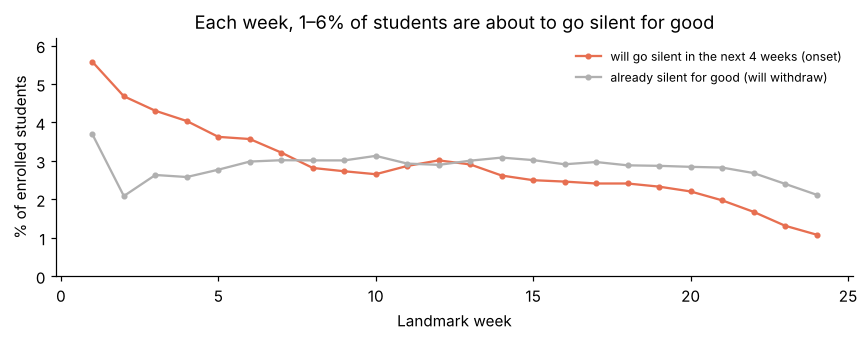

In [2]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(rates.week, rates.onset_rate * 100, marker="o", ms=3, color="#e76f51", label="will go silent in the next 4 weeks (onset)")
ax.plot(rates.week, rates.already_silent_rate * 100, marker="o", ms=3, color="#b0b0b0", label="already silent for good (will withdraw)")
ax.set(xlabel="Landmark week", ylabel="% of enrolled students", ylim=(0, 6.2),
       title="Each week, 1–6% of students are about to go silent for good")
ax.legend(frameon=False, fontsize=8); fig.tight_layout(); fig.savefig(FIG / "stage3_event_rates.png", bbox_inches="tight"); plt.show()

## 2. Who catches students before they go silent?

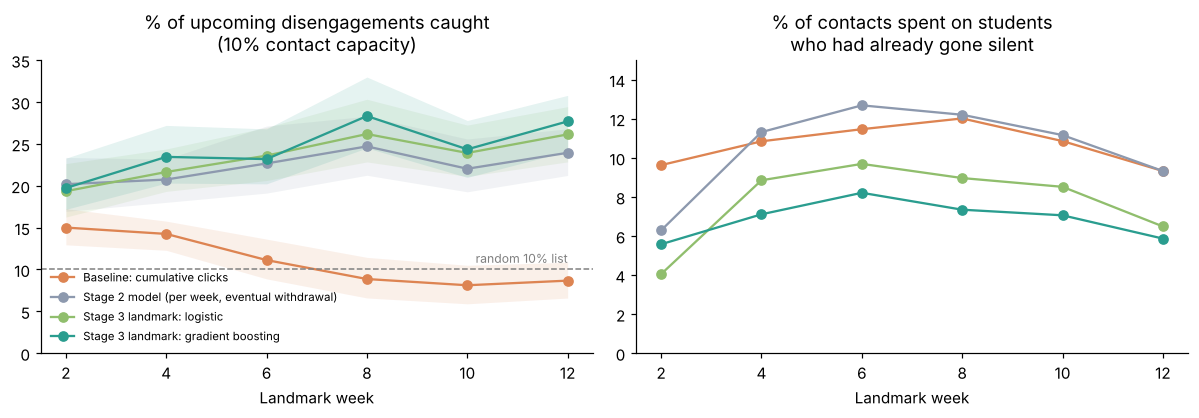

In [3]:
colours = {"Baseline: cumulative clicks": "#DD8452", "Stage 2 model (per week, eventual withdrawal)": "#8d99ae",
           "Stage 3 landmark: logistic": "#90be6d", "Stage 3 landmark: gradient boosting": "#2a9d8f"}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for name, c in colours.items():
    r = met[met.score == name]
    axes[0].plot(r.week, r.recall * 100, marker="o", color=c, label=name)
    axes[0].fill_between(r.week, r.recall_lo * 100, r.recall_hi * 100, color=c, alpha=0.12, lw=0)
    axes[1].plot(r.week, r.share_flags_already_silent * 100, marker="o", color=c)
axes[0].axhline(10, ls="--", color="grey", lw=1)
axes[0].text(12, 10.8, "random 10% list", color="grey", fontsize=8, ha="right")
axes[0].set(title="% of upcoming disengagements caught\n(10% contact capacity)", xlabel="Landmark week", ylim=(0, 35))
axes[0].legend(frameon=False, fontsize=7.5, loc="lower left")
axes[1].set(title="% of contacts spent on students\nwho had already gone silent", xlabel="Landmark week", ylim=(0, 15))
fig.tight_layout(); fig.savefig(FIG / "stage3_onset_comparison.png", bbox_inches="tight"); plt.show()

In [4]:
cols = ["precision", "base_rate", "lift", "recall", "recall_lo", "recall_hi", "auc", "median_weeks_to_onset", "share_flags_already_silent"]
met.set_index(["week", "score"])[cols].round(3)

precision  base_rate  \
week score                                                                 
2    Baseline: cumulative clicks                        0.070      0.047   
     Stage 2 model (per week, eventual withdrawal)      0.094      0.047   
     Stage 3 landmark: logistic                         0.090      0.047   
     Stage 3 landmark: gradient boosting                0.092      0.047   
4    Baseline: cumulative clicks                        0.057      0.040   
     Stage 2 model (per week, eventual withdrawal)      0.083      0.040   
     Stage 3 landmark: logistic                         0.087      0.040   
     Stage 3 landmark: gradient boosting                0.094      0.040   
6    Baseline: cumulative clicks                        0.040      0.036   
     Stage 2 model (per week, eventual withdrawal)      0.081      0.036   
     Stage 3 landmark: logistic                         0.084      0.036   
     Stage 3 landmark: gradient boosting                0.082      0.036   
8    Baseline: cumulative clicks                        0.025      0.028   
     Stage 2 model (per week, eventual withdrawal)      0.069      0.028   
     Stage 3 landmark: logistic                         0.073      0.028   
     Stage 3 landmark: gradient boosting                0.079      0.028   
10   Baseline: cumulative clicks                        0.021      0.027   
     Stage 2 model (per week, eventual withdrawal)      0.058      0.027   
     Stage 3 landmark: logistic                         0.063      0.027   
     Stage 3 landmark: gradient boosting                0.064      0.027   
12   Baseline: cumulative clicks                        0.026      0.030   
     Stage 2 model (per week, eventual withdrawal)      0.072      0.030   
     Stage 3 landmark: logistic                         0.078      0.030   
     Stage 3 landmark: gradient boosting                0.083      0.030   

                                                     lift  recall  recall_lo  \
week score                                                                     
2    Baseline: cumulative clicks                    1.495   0.150      0.129   
     Stage 2 model (per week, eventual withdrawal)  2.011   0.202      0.169   
     Stage 3 landmark: logistic                     1.927   0.193      0.163   
     Stage 3 landmark: gradient boosting            1.965   0.197      0.172   
4    Baseline: cumulative clicks                    1.419   0.142      0.123   
     Stage 2 model (per week, eventual withdrawal)  2.066   0.207      0.180   
     Stage 3 landmark: logistic                     2.156   0.216      0.193   
     Stage 3 landmark: gradient boosting            2.336   0.234      0.203   
6    Baseline: cumulative clicks                    1.109   0.111      0.089   
     Stage 2 model (per week, eventual withdrawal)  2.258   0.227      0.191   
     Stage 3 landmark: logistic                     2.352   0.236      0.206   
     Stage 3 landmark: gradient boosting            2.310   0.232      0.202   
8    Baseline: cumulative clicks                    0.882   0.089      0.066   
     Stage 2 model (per week, eventual withdrawal)  2.460   0.247      0.212   
     Stage 3 landmark: logistic                     2.607   0.262      0.228   
     Stage 3 landmark: gradient boosting            2.821   0.283      0.245   
10   Baseline: cumulative clicks                    0.809   0.081      0.059   
     Stage 2 model (per week, eventual withdrawal)  2.197   0.220      0.193   
     Stage 3 landmark: logistic                     2.385   0.239      0.211   
     Stage 3 landmark: gradient boosting            2.428   0.243      0.210   
12   Baseline: cumulative clicks                    0.864   0.087      0.066   
     Stage 2 model (per week, eventual withdrawal)  2.385   0.239      0.212   
     Stage 3 landmark: logistic                     2.604   0.261      0.228   
     Stage 3 landmark: gradient boosting            2.759   0.277      0.24

Paired differences in **precision** for the gradient-boosting landmark model against each comparator (percentage points, 95% paired bootstrap intervals over presentations).

In [5]:
d = diff.copy()
d["precision gain (pp)"] = [f"{a*100:.1f} [{lo*100:.1f}, {hi*100:.1f}]" for a, lo, hi in zip(d.d_precision, d.d_precision_lo, d.d_precision_hi)]
d.pivot(index="week", columns="compared_with", values="precision gain (pp)")[["risk_cum", "p_stage2", "p_landmark_lr", "p_gbm_no_traj"]]

compared_with,risk_cum,p_stage2,p_landmark_lr,p_gbm_no_traj
week,,,,
2,"2.2 [1.2, 3.2]","-0.2 [-1.1, 0.8]","0.2 [-0.6, 1.0]","-0.3 [-0.8, 0.2]"
4,"3.7 [2.3, 5.2]","1.1 [-0.4, 2.6]","0.7 [-0.1, 1.6]","0.0 [-0.5, 0.6]"
6,"4.3 [2.8, 5.8]","0.2 [-0.4, 0.7]","-0.1 [-0.8, 0.4]","-0.2 [-0.6, 0.2]"
8,"5.5 [3.9, 7.0]","1.0 [0.2, 1.9]","0.6 [0.0, 1.3]","-0.3 [-0.8, 0.1]"
10,"4.3 [3.1, 5.5]","0.6 [-0.1, 1.4]","0.1 [-0.7, 1.0]","0.2 [-0.4, 0.7]"
12,"5.7 [4.2, 7.2]","1.1 [0.3, 1.9]","0.5 [-0.3, 1.2]","0.2 [-0.2, 0.6]"


## 3. Are the probabilities trustworthy?

A tutor dashboard shows a *probability*, so it must be calibrated: among students given about 5% risk, about 5% should disengage. Each point is a decile of predicted risk (weeks 2–12, out-of-fold).

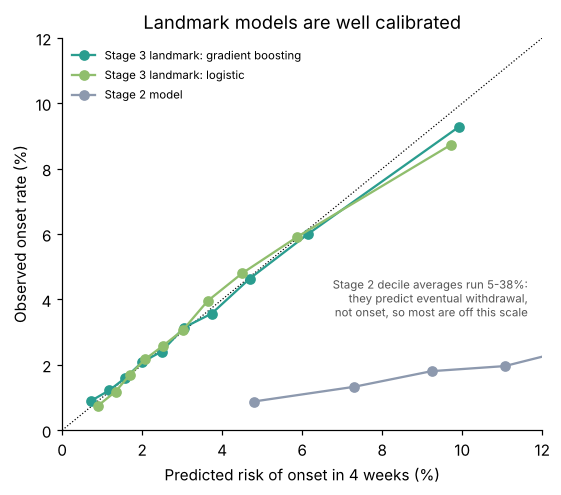

observed  \
score Stage 2 model (per week, eventual withdrawal)   
bin                                                   
0                                            0.0088   
1                                            0.0133   
2                                            0.0181   
3                                            0.0196   
4                                            0.0255   
5                                            0.0345   
6                                            0.0405   
7                                            0.0465   
8                                            0.0599   
9                                            0.0817   

                                                                      \
score Stage 3 landmark: gradient boosting Stage 3 landmark: logistic   
bin                                                                    
0                                  0.0089                     0.0075   
1                                  0.0122                     0.0118   
2                                  0.0160                     0.0170   
3                                  0.0209                     0.0217   
4                                  0.0240                     0.0257   
5                                  0.0314                     0.0306   
6                                  0.0357                     0.0396   
7                                  0.0464                     0.0480   
8                                  0.0600                     0.0591   
9                                  0.0928                     0.0873   

                                          predicted  \
score Stage 2 model (per week, eventual withdrawal)   
bin                                                   
0                                            0.0479   
1                                            0.0729   
2                                            0.0923   
3                                            0.1106   
4                                            0.1297   
5                                            0.1513   
6                                            0.1778   
7                                            0.2133   
8                                            0.2647   
9                                            0.3838   

                                                                      
score Stage 3 landmark: gradient boosting Stage 3 landmark: logistic  
bin                                                                   
0                                  0.0071                     0.0089  
1                                  0.0118                     0.0133  
2                                  0.0158                     0.0170  
3                                  0.0200                     0.0208  
4                                  0.0248                     0.0251  
5                                  0.0304                     0.0301  
6                                  0.0374                     0.0364  
7                                  0.0469                     0.0449  
8                                  0.0614                     0.0587  
9                                  0.0992                     0.0972

In [6]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
mx = 12  # stage 2 scores are mostly above this range
ax.plot([0, mx], [0, mx], color="black", lw=0.8, ls=":")
for name, c in [("Stage 3 landmark: gradient boosting", "#2a9d8f"), ("Stage 3 landmark: logistic", "#90be6d"),
                ("Stage 2 model (per week, eventual withdrawal)", "#8d99ae")]:
    t = cal[cal.score == name]
    ax.plot(t.predicted * 100, t.observed * 100, marker="o", color=c, label=name.replace(" (per week, eventual withdrawal)", ""))
ax.set(xlabel="Predicted risk of onset in 4 weeks (%)", ylabel="Observed onset rate (%)", xlim=(0, mx), ylim=(0, 12),
       title="Landmark models are well calibrated")
ax.text(mx * 0.97, 3.4, "Stage 2 decile averages run 5-38%:\nthey predict eventual withdrawal,\nnot onset, so most are off this scale", fontsize=7.5, ha="right", va="bottom", color="#555")
ax.legend(frameon=False, fontsize=7.5, loc="upper left"); fig.tight_layout(); fig.savefig(FIG / "stage3_calibration.png", bbox_inches="tight"); plt.show()
cal.pivot_table(index="bin", columns="score", values=["predicted", "observed"]).round(4)

## 4. Findings

1. **Disengagement onset is rare and hard to predict.** In any week, 3–5% of enrolled students will go silent for good in the next 4 weeks. A random 10% contact list would catch 10% of them.
2. **The landmark gradient-boosting model catches 23–28% of upcoming disengagements at 10% capacity** (weeks 4–12; 2–3× random, AUC 0.69–0.72). Every caught student is, by construction, flagged before going silent: a median of 1.3–2.3 weeks ahead.
3. **The engagement baseline is close to useless for this target.** From week 8 its precision falls to about the base rate. Low cumulative engagement identifies students who have already checked out, not those about to.
4. **The landmark model ranks students only slightly better than the stage 2 model** (+1.0–1.1 pp precision, with paired intervals excluding zero at weeks 8 and 12; earlier weeks are not significant). The main gains are elsewhere:
   * **Calibrated probabilities.** Predicted and observed rates agree within about 1 point in every decile. The stage 2 scores answer a different question (eventual withdrawal) and cannot be read as onset probabilities.
   * **Fewer wasted contacts.** 6–8% of contacts go to students who have already gone silent, against 9–13% for the stage 2 model (weeks 4–12).
   * **One model for every week,** instead of one per week.
5. **Trajectory features, retested in the nonlinear model, still add little.** See the `p_gbm_no_traj` column above. The stage 2 negative result stands.

**Limitations:** 4-week horizon only; probabilities are calibrated in aggregate (fairness by group is stage 5); folds keep presentations apart but share module identity (unseen modules are stage 6); the event depends on `last_active_day`, which is only knowable after the fact. That is correct for training labels, but the true onset of a quiet student is uncertain.